# One training step of Drive-JEPA's refiner, with auxiliary heads, on a real nuScenes keyframe

This notebook is the worked example behind **Step 1** of [docs/drivejepa-aux-heads.md](../docs/drivejepa-aux-heads.md).
It takes one nuScenes `train` keyframe and follows it through one training step:

1. the **inputs** Drive-JEPA reads, with their names, shapes and sizes;
2. the **labels** the auxiliary heads learn, built from nuScenes' annotations and map;
3. the **model**: what is frozen, what trains, what is new;
4. the **forward pass**, the **losses**, and **where each loss's gradient lands**;
5. **one optimizer step**, and proof that the frozen parts did not move.

Everything runs at batch size 1, on the released checkpoint, with the code in `src/gallops/drivejepa_aux/`.

**To run it** you need Drive-JEPA's interpreter (`{python.drivejepa}` in `gallops.toml`, Python 3.9 with
mmcv), `{code.drivejepa}` pointing at Drive-JEPA with paddock's patches applied, `{code.paddock}`, and an
extract written once by `python -m gallops.drivejepa_aux.nusc extract --out {runs}/drivejepa_aux/extract-v1`.

*Images: nuScenes (Motional), CC BY-NC-SA 4.0. Only the model's own 512 x 256 input frames are shown.*

In [1]:
import contextlib, io, os, pickle, sys, time, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent  # this notebook lives in notebooks/
sys.path.insert(0, str(REPO / "src"))
from gallops.config import SiteConfig

site = SiteConfig.load(REPO / "gallops.toml")
NUSCENES = Path(site.resolve("{data.nuscenes}"))
NAVSIM_V2 = Path(site.resolve("{code.drivejepa}")) / "navsim_v2"
EXTRACT = Path(site.resolve("{runs}")) / "drivejepa_aux" / "extract-v1"
EXP = site.resolve("{data.navsim.exp}")
CHECKPOINT = EXP + "/Drive-JEPA-cache/drive_jepa_perception_based_agent_vitl_v2.ckpt"
# the environment paddock's model.yaml gives Drive-JEPA. NAVSIM's data need not exist here -- nothing
# below reads it -- so its configured path is passed as it is, not resolved (resolving checks it exists).
NAVSIM_DATA = str(site.datasets["navsim"].path)
os.environ.update(
    NAVSIM_DEVKIT_ROOT=str(NAVSIM_V2),
    NAVSIM_EXP_ROOT=EXP,
    OPENSCENE_DATA_ROOT=NAVSIM_DATA,
    NUPLAN_MAPS_ROOT=NAVSIM_DATA + "/maps",
    NUPLAN_MAP_VERSION="nuplan-maps-v1.0",
    DRIVE_JEPA_MSDA="auto",
)
for path in (site.resolve("{code.paddock}") + "/src", str(NAVSIM_V2)):
    sys.path.insert(0, path)
os.chdir(NAVSIM_V2)  # the agent opens ./data/8192.npy and ./vjepa2/... relative to its cwd

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Patch

from gallops.drivejepa_aux import bev, heads, inputs, nusc, step, targets

pd.set_option("display.max_colwidth", 90)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("site", site.site, "| python", sys.version.split()[0], "| torch", torch.__version__,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu")

site hpcai-skodate | python 3.9.23 | torch 2.1.0+cu121 | NVIDIA H200 NVL


## 1. The keyframe

`nusc extract` read the nuScenes `v1.0-trainval` tables once for the 694 `train` scenes that are not behind
neuroNCAP (`val` is never read: paddock's nuScenes benchmark and neuroNCAP's scenarios come from it). A
**keyframe** is a 2 Hz nuScenes sample with the front frame 0.5 s earlier (within 0.05 s) and 4 s of future
keyframes, the same rule `gallops.data.nuscenes_real` uses. This one has a lead vehicle, several cars in view
and painted lane lines, so every head has something to learn from.

In [2]:
with open(EXTRACT / "extract.pkl", "rb") as f:
    data = pickle.load(f)
inputs.use_calibration(EXTRACT / "calib")
n_ticks = sum(len(v) for v in data["ticks"].values())
print(f"extract: {len(data['scenes'])} train scenes, {n_ticks} trainable keyframes")

NAME, KEYFRAME = "scene-0004", 4
scene = data["scenes"][NAME]
tick = next(t for t in data["ticks"][NAME] if t["keyframe"] == KEYFRAME)
pd.DataFrame(
    [
        ("scene", tick["scene"], "nuScenes scene, train split"),
        ("location", tick["location"], "Singapore drives on the left"),
        ("sample", tick["sample"][:12] + "...", "nuScenes sample token"),
        ("keyframe", tick["keyframe"], "index in the scene, 2 Hz"),
        ("speed", round(tick["speed"], 2), "m/s, CAN bus, as paddock's nuScenes harness reads it"),
        ("accel", round(tick["accel"], 2), "m/s^2, CAN bus"),
        ("command", tick["command"], "paddock's Command from the human's next 3 s (2 = STRAIGHT)"),
        ("expert", f"{len(tick['expert'])} x (x, y, heading)", "the human's next 4 s at 0.5 s, ego frame"),
    ],
    columns=["field", "value", "meaning"],
)

extract: 694 train scenes, 19948 trainable keyframes


,field,value,meaning
0,scene,scene-0004,"nuScenes scene, train split"
1,location,singapore-onenorth,Singapore drives on the left
2,sample,5560b4eacfe5...,nuScenes sample token
3,keyframe,4,"index in the scene, 2 Hz"
4,speed,4.82,"m/s, CAN bus, as paddock's nuScenes harness reads it"
5,accel,0.75,"m/s^2, CAN bus"
6,command,2,paddock's Command from the human's next 3 s (2 = STRAIGHT)
7,expert,"8 x (x, y, heading)","the human's next 4 s at 0.5 s, ego frame"


## 2. The model's inputs

The input builder is `swerve_data.TickDataset` (the swerve trainer's, which mirrors paddock's Drive-JEPA
adapter), fed from the extract by `inputs.TablesTickDataset`. Drive-JEPA reads **one camera, twice**: the
front frame now and 0.5 s ago, each cropped 28 rows top and bottom and resized to 512 x 256. It reads the
**last** of four ego-status rows, and the projection matrix of slot 1 (the front camera) of four.

In [3]:
dataset = inputs.TablesTickDataset([tick], DEVICE, data["scenes"], str(NUSCENES))
features, target, _ = dataset.batch([0])
meaning = {
    "camera_feature_1": "front frame now, RGB 0..1 (normalised inside the model)",
    "camera_feature_2": "front frame 0.5 s ago",
    "lidar2img": "4 camera slots [b0, f0, l0, r0]; the model keeps slot 1, the front camera",
    "img_shape": "padded image size each lidar2img is divided by",
    "ego_status": "4 frames x [pose x, y, heading | velocity 2 | acceleration 2 | command one-hot 4]; the model reads the last",
    "camera_feature": "4-view tensor the vendor's feature builder makes; nothing reads it",
}
def size(n_bytes):
    return f"{n_bytes} B" if n_bytes < 1024 else f"{n_bytes / 1024:,.0f} KiB"


rows = []
for key, value in features.items():
    if hasattr(value, "shape"):
        rows.append((key, tuple(value.shape), str(value.dtype).replace("torch.", ""),
                     size(value.numel() * value.element_size()), meaning.get(key, "")))
rows.append(("target (expert)", tuple(target.shape), "float32", size(target.numel() * 4), "the planning label: 8 poses x (x, y, heading)"))
pd.DataFrame(rows, columns=["name", "shape", "dtype", "size", "what it is"])

,name,shape,dtype,size,what it is
0,camera_feature,"(1, 4, 3, 384, 640)",float32,"11,520 KiB",4-view tensor the vendor's feature builder makes; nothing reads it
1,img_shape,"(1, 4, 3)",float32,48 B,padded image size each lidar2img is divided by
2,lidar2img,"(1, 4, 4, 4)",float32,256 B,"4 camera slots [b0, f0, l0, r0]; the model keeps slot 1, the front camera"
3,camera_feature_1,"(1, 3, 256, 512)",float32,"1,536 KiB","front frame now, RGB 0..1 (normalised inside the model)"
4,camera_feature_2,"(1, 3, 256, 512)",float32,"1,536 KiB",front frame 0.5 s ago
5,ego_status,"(1, 4, 11)",float32,176 B,"4 frames x [pose x, y, heading | velocity 2 | acceleration 2 | command one-hot 4]; the..."
6,target (expert),"(1, 8, 3)",float32,96 B,"the planning label: 8 poses x (x, y, heading)"


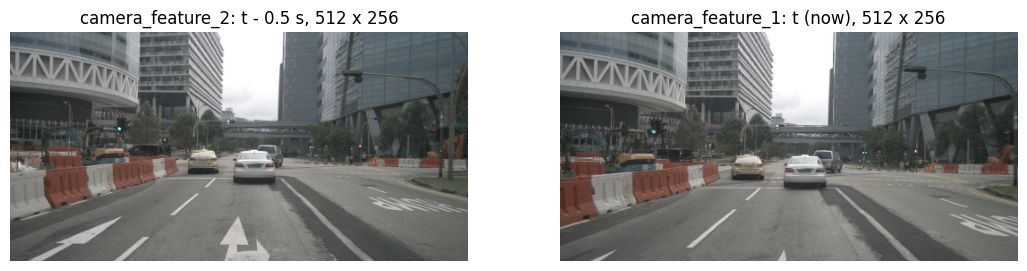

,pose x,pose y,heading,vel x,vel y,acc x,acc y,cmd left,cmd straight,cmd right,cmd unknown
"ego_status[:, -1]",0.0,0.0,-0.0,4.82,0.0,0.748,0.0,0.0,1.0,0.0,0.0


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a, key, title in zip(ax, ["camera_feature_2", "camera_feature_1"], ["t - 0.5 s", "t (now)"]):
    a.imshow(features[key][0].permute(1, 2, 0).cpu().numpy())
    a.set_title(f"{key}: {title}, 512 x 256"); a.axis("off")
plt.show()
ego = features["ego_status"][0, -1].cpu().numpy()
names = ["pose x", "pose y", "heading", "vel x", "vel y", "acc x", "acc y", "cmd left", "cmd straight", "cmd right", "cmd unknown"]
pd.DataFrame([np.round(ego, 3)], columns=names, index=["ego_status[:, -1]"])

## 3. The labels

Built by `nusc.keyframe_labels` from three nuScenes sources, then filtered by two rules: **label only what
the front camera sees** (cells and boxes outside its view are *ignored*, not called empty), and **a missing
label costs nothing** (no lead vehicle, no lane: masked).

| label | source | rule |
|---|---|---|
| BEV map, 8 classes, 128 x 256 at 0.25 m | map expansion (road, walkway, centreline, lane dividers) + 3D boxes (vehicles, pedestrians, static objects) | upstream's grid and classes, plus lane dividers; ignore outside the camera's view |
| up to 30 boxes (x, y, heading, length, width) | 3D boxes, `vehicle.*` | on the grid and centre seen by the camera; nearest first |
| lead vehicle: present, gap, closing speed | 3D boxes + their tracks | nearest vehicle ahead whose footprint overlaps the band the ego sweeps along its logged path, within 50 m |
| lane change in the next 4 s: keep / left / right | ego poses + map lane graph | ends in a lane the graph does not lead to **and** moved >= 2 m across its starting lane |

In [5]:
t0 = time.time()
view_map = nusc.MapView(nusc.devkit_map(NUSCENES, scene["location"]))
labels = nusc.keyframe_labels(scene, tick, data["annotations"][tick["sample"]], view_map)
print(f"map indexed and labels built in {time.time() - t0:.1f} s")
summary = [
    ("bev", labels["bev"].shape, "uint8", f"classes {sorted(set(np.unique(labels['bev'])) - {bev.IGNORE})}, {np.mean(labels['bev'] == bev.IGNORE):.0%} ignored"),
    ("agent_states", labels["agent_states"].shape, "float32", f"{int(labels['agent_valid'].sum())} valid boxes"),
    ("agent_valid", labels["agent_valid"].shape, "bool", ""),
    ("lead_present", "()", "int", labels["lead_present"]),
    ("lead_gap", "()", "float", f"{labels['lead_gap']:.1f} m (ego origin to the lead's rear)"),
    ("lead_closing", "()", "float", f"{labels['lead_closing']:+.2f} m/s (positive: gaining on it)"),
    ("lane_change", "()", "int", targets.LANE_CHANGE_CLASSES[labels["lane_change"]] if labels["lane_change"] >= 0 else "unknown"),
]
pd.DataFrame(summary, columns=["label", "shape", "dtype", "this keyframe"])

map indexed and labels built in 0.6 s


,label,shape,dtype,this keyframe
0,bev,"(128, 256)",uint8,"classes [0, 1, 2, 3, 4, 5, 6, 7], 72% ignored"
1,agent_states,"(30, 5)",float32,5 valid boxes
2,agent_valid,"(30,)",bool,
3,lead_present,(),int,1
4,lead_gap,(),float,16.2 m (ego origin to the lead's rear)
5,lead_closing,(),float,+0.24 m/s (positive: gaining on it)
6,lane_change,(),int,keep


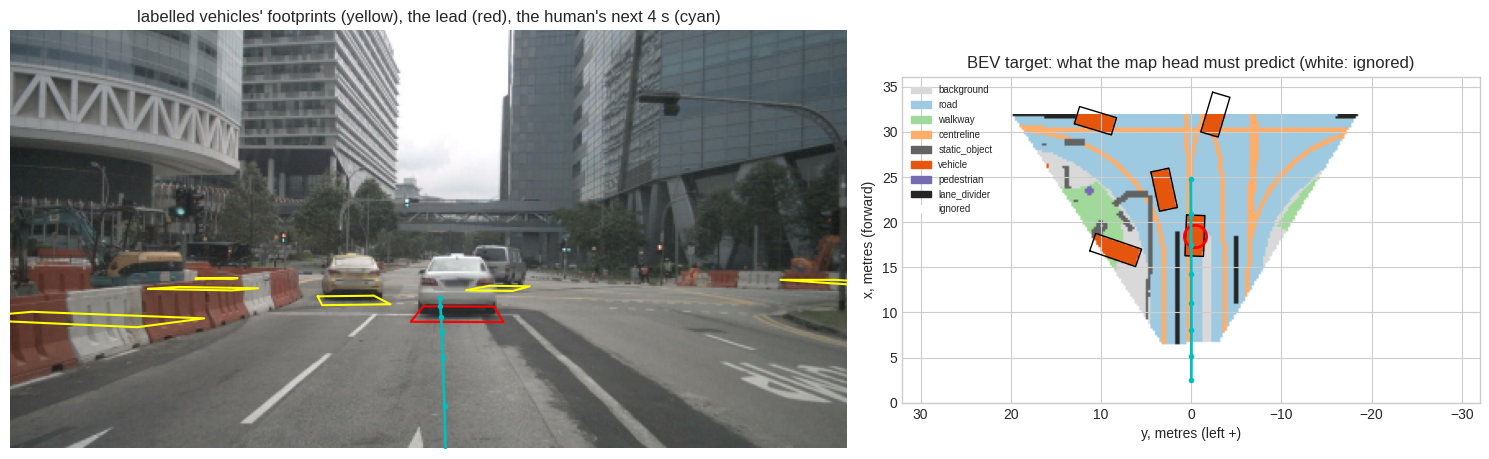

In [6]:
CLASS_COLOURS = ["#d9d9d9", "#9ecae1", "#a1d99b", "#fdae6b", "#636363", "#e6550d", "#756bb1", "#252525"]


def show_bev(ax, grid, title):
    # bev[i, j]: x = (i + 0.5) * 0.25 forward, y = (j + 0.5) * 0.25 - 32, left positive. Flip both axes to
    # draw forward up and left on the left.
    rgb = np.ones(grid.shape + (3,))
    for c, colour in enumerate(CLASS_COLOURS):
        rgb[grid == c] = plt.matplotlib.colors.to_rgb(colour)
    ax.imshow(rgb[::-1, ::-1], extent=[bev.Y_HALF, -bev.Y_HALF, 0, bev.X_MAX])
    ax.set_xlabel("y, metres (left +)"); ax.set_ylabel("x, metres (forward)"); ax.set_title(title)


def to_model_pixels(uv, height=900):
    # the model's frame is rows 28..872 of the 1600 x 900 image, resized to 512 x 256
    return np.stack([uv[:, 0] * 512 / 1600, (uv[:, 1] - nusc.MODEL_CROP_ROWS) * 256 / (height - 2 * nusc.MODEL_CROP_ROWS)], 1)


camera = scene["calibration"]["CAM_FRONT"]
K, cam2ego = np.asarray(camera["intrinsics"]), np.asarray(camera["pose"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.45, 1]})
ax[0].imshow(features["camera_feature_1"][0].permute(1, 2, 0).cpu().numpy())
vehicles, centres, _ = nusc._boxes(data["annotations"][tick["sample"]], np.asarray(scene["keyframes"][KEYFRAME]["ego"]), nusc.VEHICLE)
for i, (box, centre) in enumerate(zip(vehicles, centres)):
    if not labels["vehicles_seen"][i]:
        continue
    # the box's footprint on the ground (z = 0 in the ego frame)
    uv, depth = bev.project(np.c_[bev.box_corners(*box[:5]), np.zeros(4)], K, cam2ego)
    if (depth > 0).all():
        p = to_model_pixels(uv)
        colour = "red" if i == labels["lead_index"] else "yellow"
        ax[0].plot(np.r_[p[:, 0], p[0, 0]], np.r_[p[:, 1], p[0, 1]], color=colour, lw=1.5)
path = np.asarray(tick["expert"])
uv, depth = bev.project(np.c_[path[:, :2], np.zeros(len(path))], K, cam2ego)
p = to_model_pixels(uv[depth > 0]); ax[0].plot(p[:, 0], p[:, 1], "c.-", lw=2)
ax[0].set_xlim(0, 512); ax[0].set_ylim(256, 0); ax[0].axis("off")
ax[0].set_title("labelled vehicles' footprints (yellow), the lead (red), the human's next 4 s (cyan)")

show_bev(ax[1], labels["bev"], "BEV target: what the map head must predict (white: ignored)")
for s, v in zip(labels["agent_states"], labels["agent_valid"]):
    if v:
        c = bev.box_corners(*s); ax[1].plot(np.r_[c[:, 1], c[0, 1]], np.r_[c[:, 0], c[0, 0]], "k-", lw=1)
if labels["lead_present"]:
    lead = labels["vehicles"][labels["lead_index"]]; ax[1].plot(lead[1], lead[0], "ro", mfc="none", ms=16, mew=2)
ax[1].plot(path[:, 1], path[:, 0], "c.-", lw=2)
ax[1].legend(handles=[Patch(color=c, label=n) for c, n in zip(CLASS_COLOURS, bev.CLASSES)] + [Patch(color="white", label="ignored")],
             loc="upper left", fontsize=7, framealpha=0.9)
plt.tight_layout(); plt.show()

A lane change, for the fourth head (scene-0005, keyframe 10). Green: the lanes holding the ego now; red: the
lane holding it 4 s later; black: lane and road dividers; blue: the human's path.

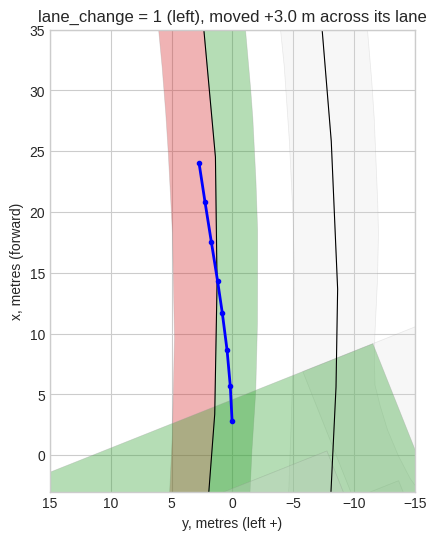

In [7]:
NAME2, KEYFRAME2 = "scene-0005", 10
scene2 = data["scenes"][NAME2]
tick2 = next(t for t in data["ticks"][NAME2] if t["keyframe"] == KEYFRAME2)
labels2 = nusc.keyframe_labels(scene2, tick2, data["annotations"][tick2["sample"]], view_map)
pose2 = np.asarray(scene2["keyframes"][KEYFRAME2]["ego"])
fig, ax = plt.subplots(figsize=(5, 6))
for token, polygon in view_map.lanes.items():
    if not view_map._near(np.array(polygon.bounds), pose2[0, 3], pose2[1, 3], 45):
        continue
    xy = nusc._to_ego_2d(np.asarray(polygon.exterior.coords), pose2)
    colour = "tab:green" if token in labels2["lanes_now"] else "tab:red" if token in labels2["lanes_later"] else "0.85"
    ax.fill(xy[:, 1], xy[:, 0], color=colour, alpha=0.35 if colour != "0.85" else 0.2, ec="0.6", lw=0.5)
for coords, bounds in view_map.dividers:
    if view_map._near(bounds, pose2[0, 3], pose2[1, 3], 45):
        xy = nusc._to_ego_2d(coords, pose2); ax.plot(xy[:, 1], xy[:, 0], "k-", lw=0.8)
path2 = np.asarray(tick2["expert"]); ax.plot(path2[:, 1], path2[:, 0], "b.-", lw=2)
ax.set_xlim(15, -15); ax.set_ylim(-3, 35); ax.set_aspect("equal")
ax.set_title(f"lane_change = {labels2['lane_change']} ({targets.LANE_CHANGE_CLASSES[labels2['lane_change']]}), "
             f"moved {labels2['lane_shift']:+.1f} m across its lane")
ax.set_xlabel("y, metres (left +)"); ax.set_ylabel("x, metres (forward)"); plt.show()

How often each label exists, over the first 30 scenes of the extract. This decides how much each head can
learn: a head whose label is rare gets few gradients.

In [8]:
counts = {"keyframes": 0, "lead present": 0, "keep": 0, "left": 0, "right": 0, "lane unknown": 0, "no box in view": 0}
class_cells = np.zeros(len(bev.CLASSES)); boxes_seen = []
maps = {scene["location"]: view_map}
t0 = time.time()
for name in [n for n in data["ticks"] if data["ticks"][n]][:30]:
    sc = data["scenes"][name]
    if sc["location"] not in maps:
        maps[sc["location"]] = nusc.MapView(nusc.devkit_map(NUSCENES, sc["location"]))
    for t in data["ticks"][name]:
        lab = nusc.keyframe_labels(sc, t, data["annotations"].get(t["sample"], []), maps[sc["location"]])
        counts["keyframes"] += 1
        counts["lead present"] += lab["lead_present"]
        counts[["keep", "left", "right", "lane unknown"][lab["lane_change"]]] += 1
        boxes_seen.append(int(lab["agent_valid"].sum())); counts["no box in view"] += int(lab["agent_valid"].sum() == 0)
        visible = lab["bev"][lab["bev"] != bev.IGNORE]
        class_cells += np.bincount(visible, minlength=len(bev.CLASSES))
print(f"{counts['keyframes']} keyframes in {time.time() - t0:.0f} s; boxes in view per keyframe: mean {np.mean(boxes_seen):.2f}, max {max(boxes_seen)}")
display(pd.DataFrame([counts]))
pd.DataFrame([np.round(class_cells / class_cells.sum() * 100, 2)], columns=bev.CLASSES, index=["% of visible cells"])

808 keyframes in 44 s; boxes in view per keyframe: mean 0.82, max 5


,keyframes,lead present,keep,left,right,lane unknown,no box in view
0,808,124,774,24,10,0,407


,background,road,walkway,centreline,static_object,vehicle,pedestrian,lane_divider
% of visible cells,40.94,37.5,10.52,7.19,0.26,1.57,0.11,1.93


## 4. The model: what is frozen, what trains, what is new

`step.build_model` builds the released model with upstream's two heads **switched on** (`bev_map`,
`bev_agent`: config flags; their code ships with Drive-JEPA, their weights do not), loads the release with
`strict=False`, and refuses unless the only missing keys are those two heads'. Then it sets `requires_grad`
on the **refiner path** (`swerve.TRAINABLE_REFINER`: the shared refiner, the query embedding, the ego encoder)
and the heads, and on nothing else.

In [9]:
t0 = time.time()
with contextlib.redirect_stdout(io.StringIO()):  # the vendor prints the whole ViT when it builds
    agent, model, scene_heads, config = step.build_model(CHECKPOINT, DEVICE)
print(f"built in {time.time() - t0:.0f} s")
origin = {
    "refiner": "release (stored 4 times in the file: the 4 passes share one module)",
    "init_feature": "release: 32 x 8 learned trajectory queries",
    "hist_encoding": "release: ego status 11 -> 256",
    "encoder (ViT + projector)": "release: V-JEPA 2 ViT-L + Linear 1024 -> 256",
    "scorer (picks the plan)": "release",
    "map head (upstream)": "upstream code, random init",
    "box head (upstream)": "upstream code, random init",
    "lead + lane-change heads (new)": "gallops, random init",
}
rows = []
for group, params in step._groups(model, scene_heads).items():
    rows.append((group, len(params), round(sum(p.numel() for p in params) / 1e6, 3), all(p.requires_grad for p in params), origin[group]))
table = pd.DataFrame(rows, columns=["part", "tensors", "parameters (M)", "trains", "weights from"])
display(table)
print(f"trainable: {table[table.trains]['parameters (M)'].sum():.2f} M of {table['parameters (M)'].sum():.1f} M")

built in 6 s


,part,tensors,parameters (M),trains,weights from
0,refiner,42,2.321,True,release (stored 4 times in the file: the 4 passes share one module)
1,init_feature,1,0.066,True,release: 32 x 8 learned trajectory queries
2,hist_encoding,2,0.003,True,release: ego status 11 -> 256
3,encoder (ViT + projector),294,304.148,False,release: V-JEPA 2 ViT-L + Linear 1024 -> 256
4,scorer (picks the plan),30,4.705,False,release
5,map head (upstream),51,2.777,True,"upstream code, random init"
6,box head (upstream),41,2.384,True,"upstream code, random init"
7,lead + lane-change heads (new),13,0.397,True,"gallops, random init"


trainable: 7.95 M of 316.8 M


## 5. The forward pass

`step.forward` runs **the vendor's own forward**, unchanged and in eval mode, and captures three tensors on the
way with hooks: the image tokens, the query features after each of the 4 refinement passes, and the scorer's
input. The heads then read the **last pass's query features**: the same tensor the scorer reads, and the one
made by the part that trains.

```
front frame t-0.5 s, t ──► ViT-L + projector (frozen) ──► 512 image tokens x 256
ego status ──► hist_encoding ─┐
32 x 8 learned queries ───────┴─► refiner, pass 1..4 (trains) ──► query features 256 x 256 ──┬─► 32 plans x 8 poses
          (each pass samples the image at its own candidates' footprints)                   ├─► scorer (frozen) ──► the plan
                                                                                             └─► aux heads (train) ──► labels
```

In [10]:
with torch.no_grad():
    t0 = time.time()
    first = step.forward(model, scene_heads, features, keep=True)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
print(f"forward in {(time.time() - t0) * 1000:.0f} ms")
out = first["out"]
rows = [
    ("image tokens", tuple(first["tokens"].shape), "(cameras, tokens, batch, channels): 2 frames x 256 x 512 -> a 16 x 32 grid of tubelets"),
    ("query features, pass 1..4", tuple(first["passes"][0].shape), "(batch, 32 proposals x 8 poses, channels)"),
    ("proposals, per pass", tuple(out["proposal_list"][0].shape), "(batch, proposals, poses, (x, y, heading))"),
    ("scorer logits", tuple(out["pred_logit"].shape), "(batch, proposals, 6 sub-scores); column 5 picks"),
    ("picked plan", tuple(out["trajectory"].shape), f"proposal {int(out['pdm_score'].argmax())} of 32"),
]
rows += [(f"aux: {k}", tuple(v.shape), "") for k, v in first["aux"].items()]
pd.DataFrame(rows, columns=["tensor", "shape", "layout"])

forward in 182 ms


,tensor,shape,layout
0,image tokens,"(1, 512, 1, 256)","(cameras, tokens, batch, channels): 2 frames x 256 x 512 -> a 16 x 32 grid of tubelets"
1,"query features, pass 1..4","(1, 256, 256)","(batch, 32 proposals x 8 poses, channels)"
2,"proposals, per pass","(1, 32, 8, 3)","(batch, proposals, poses, (x, y, heading))"
3,scorer logits,"(1, 32, 6)","(batch, proposals, 6 sub-scores); column 5 picks"
4,picked plan,"(1, 8, 3)",proposal 17 of 32
5,aux: bev,"(1, 8, 128, 256)",
6,aux: agent_states,"(1, 30, 5)",
7,aux: agent_labels,"(1, 30)",
8,aux: lead,"(1, 3)",
9,aux: lane_change,"(1, 3)",


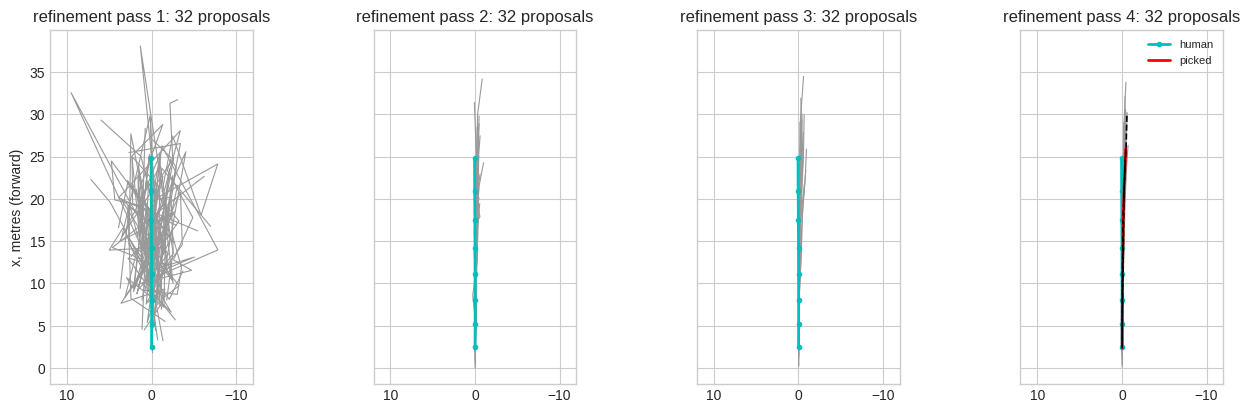

dashed: the pseudo-teachers, the release's own top 2 by its scorer
upstream heads, as run here vs as Scorer.forward runs them in training mode, max |difference|: 0.0


In [11]:
teachers, n_teachers = step.release_teachers(out)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.6), sharey=True)
for i, (a, props) in enumerate(zip(ax, out["proposal_list"])):
    p = props[0].detach().cpu().numpy()
    for traj in p:
        a.plot(traj[:, 1], traj[:, 0], color="0.6", lw=0.8)
    a.plot(path[:, 1], path[:, 0], "c.-", lw=2, label="human")
    if i == 3:
        pick = out["trajectory"][0].cpu().numpy(); a.plot(pick[:, 1], pick[:, 0], "r-", lw=2, label="picked")
        for t in teachers[0].cpu().numpy():
            a.plot(t[:, 1], t[:, 0], "k--", lw=1.2)
        a.legend(fontsize=8)
    a.set_title(f"refinement pass {i + 1}: 32 proposals"); a.set_xlim(12, -12); a.set_aspect("equal")
ax[0].set_ylabel("x, metres (forward)")
plt.show()
print("dashed: the pseudo-teachers, the release's own top 2 by its scorer")
print("upstream heads, as run here vs as Scorer.forward runs them in training mode, max |difference|:", step.check_heads(model, first))

## 6. The losses

```
total = planning + sum_k  weight_k * aux_k

planning  = sum over the 4 passes (later passes count more: loss <- 0.1 * loss + pass loss) of
            min over the 32 proposals of L1(proposal, human)                 # winner-takes-all
          + 0.5 * mean over the 2 teachers of min over the 32 proposals of L1(proposal, teacher)
            -- drivejepa_b2d.train_generator.mtd_loss, imported
bev       = cross-entropy over the 8 classes, ignored cells excluded         (weight 1.0, upstream's)
agent     = upstream's Hungarian loss: class BCE (1.0) + box L1 (0.1)
lead      = BCE on present + smooth L1 on gap / 10 m and closing / 5 m/s    (0.5 each, ours)
lane      = cross-entropy over keep / left / right, unknown excluded        (0.5, ours)
```

In [12]:
labels_t = heads.collate([labels], DEVICE)
result = step.forward(model, scene_heads, features)
terms = step.loss(result, labels_t, target, teachers, n_teachers, config)
weight = heads.weights(config)
rows = []
for name, value in terms.items():
    if name == "total":
        continue
    w = 1.0 if name == "planning" else weight[name]
    rows.append((name, round(float(value), 4), w, round(float(value) * w, 4)))
table = pd.DataFrame(rows, columns=["term", "value", "weight", "weighted"])
table["share of total"] = (table.weighted / table.weighted.sum() * 100).round(1).astype(str) + " %"
display(table)
print(f"total = {float(terms['total']):.4f}.  At random init the classification terms sit at chance: "
      f"bev {np.log(8):.2f} = ln 8, lead_present {np.log(2):.2f} = ln 2, lane_change {np.log(3):.2f} = ln 3.")

,term,value,weight,weighted,share of total
0,planning,0.3675,1.0,0.3675,4.5 %
1,bev,2.0562,1.0,2.0562,24.9 %
2,agent_class,0.5917,1.0,0.5917,7.2 %
3,agent_box,36.7624,0.1,3.6762,44.5 %
4,lead_present,0.6711,0.5,0.3356,4.1 %
5,lead_gap,1.3006,0.5,0.6503,7.9 %
6,lead_closing,0.0192,0.5,0.0096,0.1 %
7,lane_change,1.1333,0.5,0.5666,6.9 %


total = 8.2536.  At random init the classification terms sit at chance: bev 2.08 = ln 8, lead_present 0.69 = ln 2, lane_change 1.10 = ln 3.


## 7. How the refiner is fine-tuned: where each loss's gradient lands

This is the point of the design. The heads read the refiner's query features, so every auxiliary loss
sends a gradient **back through the heads into the refiner** (and into the query embedding and the ego
encoder). The planning loss sends one there too. Neither reaches the encoder or the scorer: they have no
`requires_grad`.

`step.gradient_split` takes each loss term alone and measures its gradient on each trainable part, without
stepping. The last column compares the refiner's planning gradient with its auxiliary gradient: a cosine
above 0 means the auxiliary labels push the refiner the same way the planning loss does.

,refiner,init_feature,hist_encoding,map head (upstream),box head (upstream),lead + lane-change heads (new)
planning,37.1137,0.2684,4.3043,0.0000,0.0000,0.0000
auxiliary (all),1.4393,0.0067,0.1445,0.5816,3.8768,3.1977
aux: bev,0.0109,0.0000,0.0010,0.5816,0.0000,0.0000
aux: agent_class,0.5369,0.0024,0.0469,0.0000,3.1715,0.0000
aux: agent_box,0.4308,0.0022,0.0497,0.0000,2.2406,0.0000
aux: lead_present,0.4033,0.0018,0.0373,0.0000,0.0000,1.1198
aux: lead_gap,0.9042,0.0040,0.0830,0.0000,0.0000,2.2360
aux: lead_closing,0.1765,0.0008,0.0164,0.0000,0.0000,0.4558
aux: lane_change,0.7089,0.0035,0.0753,0.0000,0.0000,1.9047


cosine between the planning and the auxiliary gradient on the refiner: +0.035


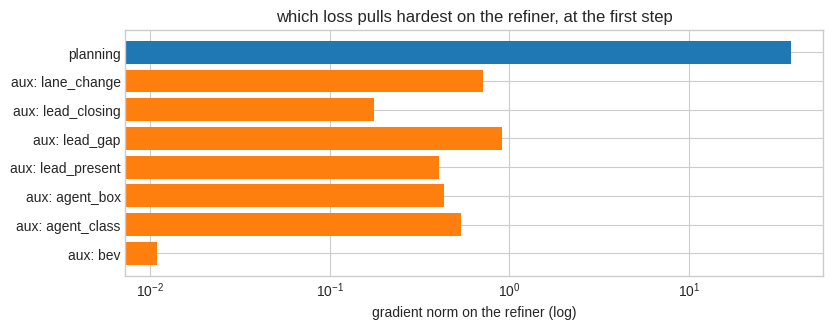

In [13]:
split = step.gradient_split(model, scene_heads, features, labels_t, target, teachers, n_teachers, config)
norms = pd.DataFrame(split["norms"]).T
display(norms.round(4))
print(f"cosine between the planning and the auxiliary gradient on the refiner: {split['refiner_cosine']:+.3f}")
fig, ax = plt.subplots(figsize=(9, 3.2))
refiner = norms["refiner"].drop(["planning", "auxiliary (all)"])
ax.barh(list(refiner.index) + ["planning"], list(refiner.values) + [norms.loc["planning", "refiner"]],
        color=["tab:orange"] * len(refiner) + ["tab:blue"])
ax.set_xscale("log"); ax.set_xlabel("gradient norm on the refiner (log)")
ax.set_title("which loss pulls hardest on the refiner, at the first step"); plt.show()

At the first step the heads are random, so what they send into the refiner carries no information yet.
The table above says how much that is: on this keyframe the auxiliary gradient on the refiner is a few per
cent of the planning gradient, and its cosine with it is near 0. Small, but noise. A **warm-up** removes it
until the heads have learned something: `forward(..., detach_heads=True)` feeds the heads a detached copy of
the query features, so the heads train and the refiner sees the planning gradient alone. The table below
checks the switch does exactly that.

In [14]:
def refiner_grad_norm(detach_heads):
    model.zero_grad(set_to_none=True); scene_heads.zero_grad(set_to_none=True)
    res = step.forward(model, scene_heads, features, detach_heads=detach_heads)
    t = step.loss(res, labels_t, target, teachers, n_teachers, config)
    t["total"].backward()
    refiner = [p.grad for n, p in model.named_parameters() if n.startswith("_trajectory_head") and p.grad is not None]
    head = [p.grad for p in scene_heads.parameters() if p.grad is not None]
    norm = lambda gs: float(torch.sqrt(sum((g ** 2).sum() for g in gs))) if gs else 0.0
    return norm(refiner), norm(head)

joint, warm = refiner_grad_norm(False), refiner_grad_norm(True)
model.zero_grad(set_to_none=True); scene_heads.zero_grad(set_to_none=True)
pd.DataFrame(
    [("joint", *joint), ("warm-up (detach_heads)", *warm), ("planning alone (arm C)", norms.loc["planning", "refiner"], 0.0)],
    columns=["mode", "refiner gradient norm", "new heads' gradient norm"],
).round(4)

,mode,refiner gradient norm,new heads' gradient norm
0,joint,37.1926,3.1977
1,warm-up (detach_heads),37.1137,3.1977
2,planning alone (arm C),37.1137,0.0000


## 8. One optimizer step

`step.train_step` zeroes the gradients, runs the forward and the loss, backpropagates and steps Adam: the
refiner path at 2e-5 (the Bench2Drive generator stage's rate), the heads at 1e-4 (the release's own rate:
they start from random weights). It reports, per part, the gradient and the size of the update. A frozen
part's update is measured as the change in its checksum.

In [15]:
opt = step.make_optimizer(model, scene_heads)
print([(g["name"], g["lr"], sum(p.numel() for p in g["params"])) for g in opt.param_groups])
before = step.forward(model, scene_heads, features)["out"]["proposal_list"][-1].detach().clone()
t0 = time.time()
report = step.train_step(model, scene_heads, opt, features, labels_t, target, teachers, n_teachers, config)
print(f"one step (forward + backward + Adam) in {(time.time() - t0) * 1000:.0f} ms; "
      f"peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB" if DEVICE == "cuda" else "")
display(pd.DataFrame(report["groups"]).T.astype({"tensors": int, "parameters": int}))
with torch.no_grad():
    after_result = step.forward(model, scene_heads, features)
    after = after_result["out"]["proposal_list"][-1]
    after_terms = step.loss(after_result, labels_t, target, teachers, n_teachers, config)
moved = (after - before)[0, :, :, :2].norm(dim=-1)
print(f"the 32 proposals moved by {float(moved.mean()) * 100:.2f} cm on average (max {float(moved.max()) * 100:.2f} cm)")
pd.DataFrame({"before the step": report["terms"], "after the step": {k: float(v) for k, v in after_terms.items()}}).round(4)

[('refiner path', 2e-05, 2389827), ('heads', 0.0001, 5557268)]
one step (forward + backward + Adam) in 70 ms; peak GPU memory 1.58 GiB


,tensors,parameters,trainable,grad_norm,update_norm
refiner,42,2321219,True,37.192581,0.03013
init_feature,1,65536,True,0.269104,0.005067
hist_encoding,2,3072,True,4.330989,0.00064
encoder (ViT + projector),294,304147712,False,None,0.0
scorer (picks the plan),30,4704992,False,None,0.0
map head (upstream),51,2776584,True,0.581551,0.162014
box head (upstream),41,2383878,True,3.87675,0.153995
lead + lane-change heads (new),13,396806,True,3.197747,0.057558


the 32 proposals moved by 20.25 cm on average (max 57.33 cm)


,before the step,after the step
planning,0.3675,0.3269
bev,2.0562,2.0525
agent_class,0.5917,0.5110
agent_box,36.7624,36.2184
lead_present,0.6711,0.6500
lead_gap,1.3006,1.2241
lead_closing,0.0192,0.0166
lane_change,1.1333,1.0811
total,8.2536,7.9982


## What one step is

* **Inputs:** two 512 x 256 front frames, one 11-number ego vector, the front camera's projection.
* **Labels:** a 128 x 256 BEV class map (ignored outside the camera's view), up to 30 boxes, a lead vehicle,
  a lane change; plus the human's 4 s, which the planning loss uses.
* **What trains:** the refiner path (2.39 M parameters, the release's) and the heads (5.56 M, new). The
  304 M-parameter encoder and the scorer do not, and the checksums say so.
* **How the auxiliary labels reach the planner:** through the query features. The heads read them, so every
  auxiliary gradient flows back into the refiner that makes them, and from there into the 32 proposals and
  into what the frozen scorer sees.
* **What is not changed:** the inference graph. In eval mode the upstream heads do not run; the new heads exist
  only in the trainer; the served file is the release with the refiner path's tensors replaced, so paddock's
  `drivejepa` adapter serves it as it is.